# Multi-SDE research through the Afon data fabric

## Objective of the Notebook

- Demonstrate how synthetic data held in multiple SDEs can be automatically brought together whilst maintaining local governance control and minimising data movement through a representative research question.
- Compare this approach to single SDE analysis eyes off federated analysis


### Research Context

Epidermal growth factor receptor (EGFR) mutations are the most common oncogenic drivers in non-small-cell lung cancer (NSCLC). This project uses synthetic real world data to estimate the impact of different treatment regimens on patient outcomes


**Research Question.** Among patients with advanced (stage IIIB/IV) EGFR-mutant NSCLC, does first-line
osimertinib reduce 12-month progression compared with a platinum doublet?

**Setting.** We are linking data between the WestMidlands SDE (Azure), Thames Valley and Surrey SDE (Azure) and a central data store (AWS) each holding their own FHIR-derived data.

**Data**
FIHR data held by each SDE, patients, observations, prescriptions, outcomes

**Plan.**
1. Access the data
2. Show the causal diagram 
3. Estimate the effects using single SDE, eyes off and eyes on approaches 
4. Compare this to the ground truth

## 1. Access data from each SDE

Each site creates the input dataa locally on its own four FHIR tables. The output is one row
per eligible patient with baseline covariates (last value on or before treatment start), a binary
treatment indicator and the 12-month outcome.

#### Accessing data in the westmidlands SDE cloud via a Polaris catalog token 

In [26]:
spark.sql(f"DESCRIBE TABLE EXTENDED {westmids_table}").filter("col_name = 'Location'").show(truncate = False)

+--------+---------------------------------------------------------------------------------------------+-------+
|col_name|data_type                                                                                    |comment|
+--------+---------------------------------------------------------------------------------------------+-------+
|Location|abfss://afonstorage@westmidsstorageaccount.dfs.core.windows.net/namespaceph/prescription_data|       |
+--------+---------------------------------------------------------------------------------------------+-------+



####  Accessing data in the TVS cloud via a Polaris catalog token

In [27]:
spark.sql(f"DESCRIBE TABLE EXTENDED {tvs_table}").filter("col_name = 'Location'").show(truncate = False)

+--------+------------------------------------------------------------------------------------------------+-------+
|col_name|data_type                                                                                       |comment|
+--------+------------------------------------------------------------------------------------------------+-------+
|Location|abfss://afonstorage@tvsafonstorageaccount.dfs.core.windows.net/acceptancetests/prescription_data|       |
+--------+------------------------------------------------------------------------------------------------+-------+



In [29]:
frames = []
SITES = ['westmids','tvs','hdrs']
for s in SITES:
    tables = cohort.load_site(DATA / s)
    site_df = cohort.build_lung_cohort(tables, advanced_only=True)
    cohort.write_site_artifact(site_df, ROOT / "output" / s / "cohort.parquet")
    frames.append(site_df)
df = pd.concat(frames, ignore_index=True)
pos = df[df["egfr_positive"] == 1].reset_index(drop=True)
neg = df[df["egfr_positive"] == 0].reset_index(drop=True)
print(f"advanced-stage cohort: {len(df)} patients; EGFR+ {len(pos)}, EGFR- {len(neg)}")


advanced-stage cohort: 1589 patients; EGFR+ 560, EGFR- 1029


### Table one — case-mix differs by site

In [30]:
def table_one(d):
    g = d.groupby("site")
    out = pd.DataFrame({
        "n": g.size(),
        "Age": g["age"].mean().round(1),
        "Female ratio": g["female"].mean().round(2),
        "Never Smoker": g["never_smoker"].mean().round(2),
        "EFGR + ratio": g["egfr_positive"].mean().round(2)
    })
    return out

table_one(df)

,n,Age,Female ratio,Never Smoker,EFGR + ratio
site,,,,,
hdrs,583,61.2,0.53,0.15,0.32
tvs,520,60.5,0.52,0.28,0.40
westmids,486,60.8,0.50,0.20,0.34


## 2. Show the causal diagram

The assumed DAG matches clinical reasoning (and, here, the generator): age, sex, stage, ECOG,
albumin and smoking history influence both prescribing and progression. Within the EGFR+ group


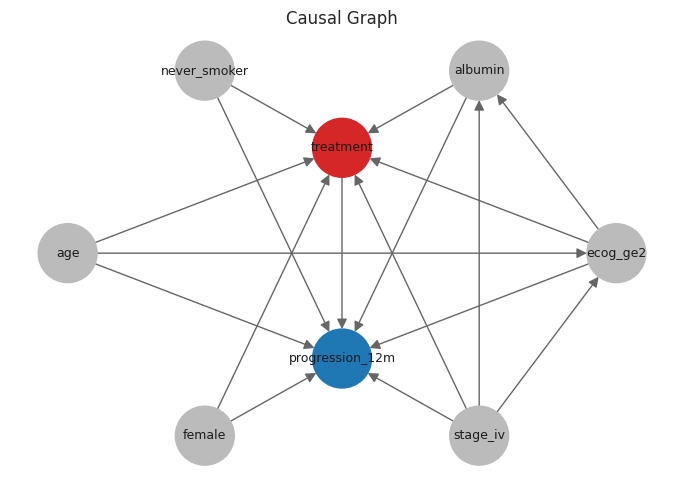

In [32]:
model, estimand = A.dowhy_model
import networkx as nx
g = A.causal_graph()
posn = nx.shell_layout(g, nlist=[[A.TREATMENT, A.OUTCOME], A.COVARIATES])
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#d62728" if n == A.TREATMENT else "#1f77b4" if n == A.OUTCOME else "#bbbbbb" for n in g.nodes]
nx.draw_networkx(g, posn, ax=ax, node_color=colors, node_size=1800, font_size=9, arrowsize=15, edge_color="#666")
ax.set_axis_off(); ax.set_title("Causal Graph")
plt.tight_layout()

## 3. Estimate the effects

A Bayesian model to test the causal graph we have seen for each site and across sites using a federated and pooled approach

In [11]:
prior = A.fit_hierarchical(df, draws=500, prior_only=True, seed=SEED)
idata = A.fit_hierarchical(df, draws=1000, tune=1000, chains=4, seed=SEED)

site_idatas = {s: A.fit_site_model(df[df["site"] == s], draws=1000, tune=1000, chains=4, seed=SEED) for s in SITES}

summaries = [A.site_summary(site_idatas[s], s) for s in SITES]

meta = A.meta_analysis(summaries, seed=SEED)


Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 12 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 13 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 15 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [mu, tau_between, z]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 10 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.

## 4. Compare against the ground truth

Now we compare these approaches with the ground truth. The target is the sample-average true
risk difference $\frac{1}{n}\sum_i (p_{1i} - p_{0i})$ over the analysed EGFR+ patients.

In [46]:
truth = A.load_truth(DATA, SITES)
tv_pos = A.true_rd(truth, pos["patient_id"], egfr=1)
tv_neg = A.true_rd(truth, neg["patient_id"], egfr=0)
tv_site = {s: A.true_rd(truth, pos.loc[pos["site"] == s, "patient_id"]) for s in SITES}
print(f"true RD  EGFR+: {tv_pos:.4f} ")


true RD  EGFR+: -0.2818 


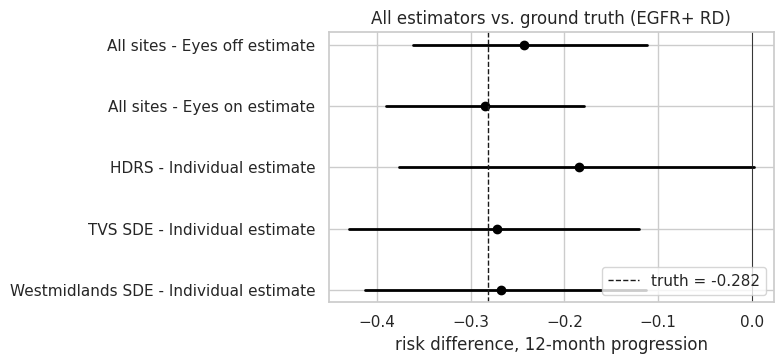

In [45]:
included_methods = ['Individual estimate','Eyes on estimate','Eyes off estimate']
## Plot the output
fig, ax = plt.subplots(figsize=(8, 0.35 * len(scored) + 1))
forest(scored.loc[scored.method.isin(included_methods),:].sort_values(["site", "method"]), truth=tv_pos, title="All estimators vs. ground truth (EGFR+ RD)", ax=ax)
plt.tight_layout()


In [42]:
bayes_rows = [
    {"site": "pooled", "method": "pymc_hierarchical", **A.posterior_interval(idata, "ate_rd_egfr_pos"), "n": len(pos)},
    {"site": "pooled", "method": "federated_meta", **A.posterior_interval(meta, "mu"), "n": len(pos)},
]
for s in SITES:
    bayes_rows.append({"site": s, "method": "pymc_no_pooling", **A.posterior_interval(site_idatas[s], "ate_rd_egfr_pos"), "n": int((pos["site"] == s).sum())})
    hd = az.hdi(idata.posterior["ate_rd_site"].sel(site=s), hdi_prob=0.95)["ate_rd_site"].to_numpy()
    bayes_rows.append({"site": s, "method": "pymc_partial_pooling", "estimate": idata.posterior["ate_rd_site"].sel(site=s).mean().item(),
                       "ci_low": float(hd[0]), "ci_high": float(hd[1]), "n": int((pos["site"] == s).sum())})
all_est = pd.concat([pd.DataFrame(bayes_rows)], ignore_index=True)
scored = A.score_estimates(all_est, tv_pos)
scored["truth"] = scored["site"].map(tv_site).fillna(tv_pos)
scored["bias"] = scored["estimate"] - scored["truth"]
scored["covered"] = (scored["ci_low"] <= scored["truth"]) & (scored["truth"] <= scored["ci_high"])
included_methods = ["pymc_no_pooling","pymc_hierarchical","federated_meta"]
scored.loc[scored.method.isin(included_methods),:].sort_values(["site", "method"]).round(3)

def forest(tbl, truth=None, title="", ax=None):
    tbl = tbl.reset_index(drop=True)
    ax = ax or plt.gca()
    labels = [f"{r.site} - {r.method}" for r in tbl.itertuples()]
    y = np.arange(len(tbl))[::-1]
    palette={"westmids" : "#1f77b4","tvs" : "#2ca02c","hdrs" : "#ff7f0e","pooled": "#7f7f7f"}
    for yi, r in zip(y,tbl.itertuples()):
        c=palette.get(r.site,"#000")
        ax.plot([r.ci_low,r.ci_high],[yi,yi],color=c,lw=2)
        ax.plot(r.estimate,yi,"o",color=c)
    if truth is not None:
        ax.axvline(truth,color="k",ls="--",lw=1,label=f"truth = {truth:.3f}")
        ax.legend(loc="lower right")
    ax.axvline(0,color="k",lw =0.6)
    ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlabel("risk difference, 12-month progression")
    ax.set_title(title)
    return ax

site_dict = {'pooled': 'All sites','hdrs': 'HDRS','tvs' :'TVS SDE', 'westmids': 'Westmidlands SDE'}
method_dict = {'pymc_no_pooling': 'Individual estimate','pymc_hierarchical': 'Eyes on estimate',
               'federated_meta' : 'Eyes off estimate','pymc_partial_pooling' : 'partial pooling'}
scored.loc[:,'site'] = scored.loc[:,'site'].map(lambda x : site_dict[x])
scored.loc[:,'method'] = scored.loc[:,'method'].map(lambda x : method_dict[x])



In [28]:
import sys, warnings
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import analysis as A
from src import cohort

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
SITES = ("aws", "azure", "gcp")
DATA = ROOT / "output"
SEED = 2024
from pyspark.sql import SparkSession
import os as os

OIDC_TOKEN = """***REMOVED_JWT***"""
spark = (SparkSession.builder.appName("test").remote("sc://spark-connector-0-driver-svc:15002")
    .config("spark.sql.catalog.westmids.scope", "openid")
    .config("spark.sql.catalog.westmids.header.X-Iceberg-Access-Delegation", "vended-credentials")
    .config("spark.sql.catalog.westmids", "org.apache.iceberg.spark.SparkCatalog")
    .config("spark.sql.catalog.westmids.type", "rest")
    .config("spark.sql.catalog.westmids.uri", "https://westmidspolarisazure.click/api/catalog")
    .config("spark.sql.catalog.westmids.cache-enabled", "false")
    .config("spark.sql.catalog.westmids.warehouse", "azure")
    .config("spark.sql.catalog.westmids.token", OIDC_TOKEN)
    .config("spark.sql.catalog.westmids.oauth2-server-uri", "https://emrysoauth.click/realms/polaris/protocol/openid-connect/token")

     .config("spark.sql.catalog.tvs.scope", "openid")
     .config("spark.sql.catalog.tvs.header.X-Iceberg-Access-Delegation", "vended-credentials")
     .config("spark.sql.catalog.tvs", "org.apache.iceberg.spark.SparkCatalog")
     .config("spark.sql.catalog.tvs.type", "rest")
     .config("spark.sql.catalog.tvs.uri", "https://westmidspolarisazure.click/api/catalog")
     .config("spark.sql.catalog.tvs.cache-enabled", "false")
     .config("spark.sql.catalog.tvs.warehouse", "azure")
     .config("spark.sql.catalog.tvs.token", OIDC_TOKEN)
     .config("spark.sql.catalog.tvs.oauth2-server-uri", "https://tvspolarisazure.click/realms/polaris/protocol/openid-connect/token")

     .config("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
     .config("spark.driver.allowMultipleContexts", "true")
     .config("spark.sql.iceberg.planning.preserve-data-grouping", "true")
     .config("spark.sql.sources.v2.bucketing.enabled", "true")
     .config("spark.sql.sources.bucketing.enabled", "true")
).getOrCreate()

print("Finished initializing spark session")

westmids_table = "westmids.namespaceph.prescription_data"
tvs_table = "azure.acceptancetests.prescription_data"


Finished initializing spark session
